In [1]:
import geojson
from quantification_utils import (
    ppm_m_to_mol_per_m2,
    ppm_m_to_mol_per_m2_v0,
    calc_L_IME,
    calc_Q_IME,
    reproject_coords
)

from wind_data import get_wind_speed_for_plume,  download_wind_data
from emit_data import get_plumes_data_metadata 

bbox = (5.027957, 30.72952, 7.027957, 32.72952)


In [2]:
def quantify_plume(
    plume_id,
    plume_data,
    plumes_coords,
    lat_plume, long_plume,
    wind_ds,
    source_ds,
    sensing_time: str,
    spatial_resolution: float = 60.0):

    # Get wind data
    u_eff, u_eff_high, u_eff_low, wind_direction, u_wind_component = get_wind_speed_for_plume(wind_ds, source_ds , lat_plume, long_plume)
    # Quantify plume
    plume_area, L, IME = calc_L_IME(data=plume_data, plumes_coords=plumes_coords, origin= (long_plume, lat_plume), spatial_res_m=spatial_resolution)
    emission_rate = calc_Q_IME(u_eff, L, IME)
    emission_rate_low = calc_Q_IME(u_eff_low, L, IME)
    emission_rate_high = calc_Q_IME(u_eff_high, L, IME)
    
    properties={
                "plume_id" : plume_id, 
                "Q": emission_rate,
                "Q_low": emission_rate_low,
                "Q_high": emission_rate_high,
                "Q_uncertainty_type": None,
                "wind_direction": wind_direction,
                "u10_wind_speed": u_wind_component,
                "u_eff_wind_speed": u_eff,
                "wind_speed_eff_upper": u_eff_high,
                "wind_speed_eff_lower": u_eff_low,
                "wind_speed_uncertainty_type": None,
                "latitude": lat_plume,
                "longitude": long_plume,
                "IME": IME,
                "length": L,
                "area": plume_area,
                "date": sensing_time.split("T")[0],
            }
    feature = geojson.Feature(
            geometry=geojson.Point((long_plume, lat_plume)),
            properties=properties,
        )   
    return properties  


In [3]:
## add segmentation to have the real plume not the plume complexe! 

def quantify_plumes(
    data_dir= "emit_ch4/EMITL2BCH4PLM",
    sensing_time : str = "20230216",
    bbox = (5.027957, 30.72952, 7.027957, 32.72952),
    spatial_resolution: float = 55.05,
    wind_source=  "GEOS_FP"
) -> list[geojson.Feature] | None:
    """
    Mask the retrieval arary using a threshold and quantify the masked plumes.

    Fields
    ------
    retrieval_array: numpy array with retrieval values
    retrieval_transform: retrieval tiff transfrom
    retrieval_crs: CRS of retrieval tile
    mask: binary mask indicating which pixels are plumes (=1)
    sensing_time: time (str) the sentinel-2 tile was captured
    """
    # Fetch wind tile for date
    wind_ds = download_wind_data(sensing_time , bbox, source=wind_source)
    if wind_ds is None:
        return None

    plumes = get_plumes_data_metadata(base_dir = data_dir , date= sensing_time, version=None) 
    results = []
    for plume_id, plume in plumes.items():

        # read plume data 

        plume_data = plumes[plume_id]['data'] 
        plume_data[plume_data == -9999] = 0
        plume_data = ppm_m_to_mol_per_m2(plume_data)
        
        # print(plume_data)
        plume_metadata = plumes[plume_id]['metadata'] 
        plumes_coords = plumes[plume_id]['geometry']['coordinates'][0]

        # latitude, longitude 
        lat_plume, long_plume = plume_metadata['Latitude of max concentration'], plume_metadata['Longitude of max concentration'] 

        # quantify one plume         
        feature = quantify_plume(plume_id, plume_data, plumes_coords, lat_plume, long_plume,
                                 wind_ds=wind_ds, source_ds= wind_source,
                                   sensing_time=sensing_time, spatial_resolution=spatial_resolution)
        feature['tif_path'] = plumes[plume_id]['tif_path'] 
        results.append(feature)
        
    return results

results = quantify_plumes(sensing_time = "20230626")

In [4]:
results = quantify_plumes(sensing_time = "20230626", wind_source="ERA5")

2025-08-20 16:45:00,417 INFO [2024-09-26T00:00:00] Watch our [Forum](https://forum.ecmwf.int/) for Announcements, news and other discussed topics.


In [5]:
import rasterio
import numpy as np

def extract_plume_coords(tif_file, threshold=0):
    """
    Extract (x, y) coordinates of plume pixels from a GeoTIFF.
    
    Parameters
    ----------
    tif_file : str
        Path to plume GeoTIFF (concentration map).
    threshold : float
        Minimum value to consider as plume (e.g., > 0, or a ppm threshold).
        
    Returns
    -------
    coords : list of tuples
        List of (x, y) coordinates in the GeoTIFF CRS.
    crs : rasterio.crs.CRS
        CRS of the coordinates (useful to reproject to meters).
    """
    with rasterio.open(tif_file) as src:
        data = src.read(1)  # first band
        transform = src.transform
        crs = src.crs

        # Find plume pixels (mask)
        plume_mask = data > threshold

        # Get row, col indices of plume pixels
        rows, cols = np.where(plume_mask)

        # Convert to (x, y) coordinates
        coords = [rasterio.transform.xy(transform, r, c) for r, c in zip(rows, cols)]

    return data, coords, crs


def quantify_plume_carbon_mapper(
    data_file= "carbon_mapper/emi20230216t133626p09013-A_l3a-ch4-mfa-v0_concentrations_2023-02-16.tif",
    sensing_time : str = "20230216",
    long_plume  =  5.99925551785579,
    lat_plume = 31.74766142315273,
    spatial_resolution: float = 60.0,
    plume_id =  "000659",
    wind_source=  "ERA5",
    bbox = (5.027957, 30.72952, 7.027957, 32.72952),
    
) -> list[geojson.Feature] | None:
    """
    Mask the retrieval arary using a threshold and quantify the masked plumes.

    Fields
    ------
    retrieval_array: numpy array with retrieval values
    retrieval_transform: retrieval tiff transfrom
    retrieval_crs: CRS of retrieval tile
    mask: binary mask indicating which pixels are plumes (=1)
    sensing_time: time (str) the sentinel-2 tile was captured
    """
    # Fetch wind tile for date
    wind_ds = download_wind_data(sensing_time , bbox, source=wind_source)
    if wind_ds is None:
        return None

    # Load raster
    plume_data, coords, crs = extract_plume_coords(data_file, threshold=0)
    plume_data = ppm_m_to_mol_per_m2(plume_data)

    # read plume data 
    # quantify one plume         
    feature = quantify_plume(plume_id, plume_data, plumes_coords = coords, 
                             long_plume =long_plume , lat_plume= lat_plume, wind_ds=wind_ds, source_ds= wind_source,
                             sensing_time=sensing_time, spatial_resolution=spatial_resolution)
        
    return feature

result = quantify_plume_carbon_mapper(plume_id = '001683', sensing_time = "20230929", data_file = "carbon_mapper/emi20230929t122534p08039-A_l3a-vis-ch4-mfa-v002_plume_2023-09-29.tif")

2025-08-20 16:45:00,784 INFO [2024-09-26T00:00:00] Watch our [Forum](https://forum.ecmwf.int/) for Announcements, news and other discussed topics.


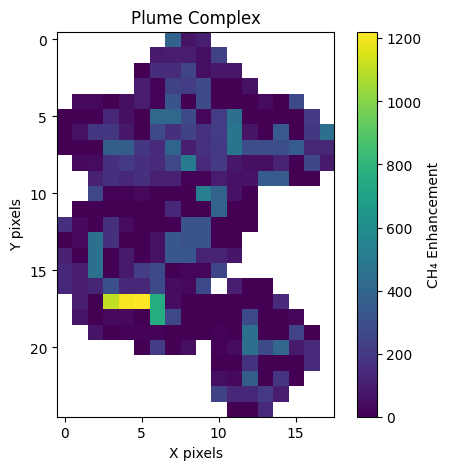

0.0 1221.0792


In [6]:
import rasterio
import matplotlib.pyplot as plt
import json
import geopandas as gpd
from rasterio.plot import show
from shapely.geometry import box


def visualize_plume_complex(tif_path):
    # --- Load raster ---
    with rasterio.open(tif_path) as src:
        data = src.read(1,  masked=True)  # first band
        # data[data == -9999] = np.nan
        bounds = src.bounds
        crs = src.crs
        plt.figure(figsize=(6, 5))
        plt.imshow(data, cmap="viridis")
        plt.colorbar(label="CH₄ Enhancement")
        plt.title(f"Plume Complex")
        plt.xlabel("X pixels")
        plt.ylabel("Y pixels")
        plt.show()
        print(np.nanmin(data), np.nanmax(data))


visualize_plume_complex("carbon_mapper/emi20230626t101232p07010-C_l3a-ch4-mfa-v1_concentrations.tif")
    

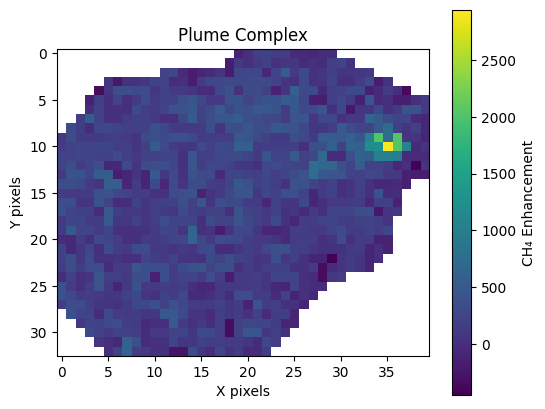

-448.5563 2944.7554


In [7]:
visualize_plume_complex("emit_ch4/EMITL2BCH4PLM/EMIT_L2B_CH4PLM_001_20230626T101232_000146.tif")


## Automaticaly validate the calculated emissions + wind + IME, with the carbon mapper based on the source plume.. 

1. in one bbox from date to date 
2. get plumes from EMITPLM
3. get the plumes using the API 
4. get the IME using stac 
5. Do the correspondance between them with the nearest point to the source point
6. add to the dataframe the emit_plume_id, calculated_Q, ..
7. visualize the emit_plume and the carbon mapper plumes in a subplot, in the title the calculate Q and the carbon mapper Q  
8. calculate the error  

In [8]:
import matplotlib.pyplot as plt
import rasterio
from rasterio.plot import show
import pandas as pd
from datetime import datetime
from math import radians, sin, cos, sqrt, atan2
from carbonmapper import CarbonMapperAuth, get_carbonmapper_plumes, get_IME_data
import requests
import os
from urllib.parse import urlparse, unquote
import matplotlib.pyplot as plt
import seaborn as sns
import rasterio
import numpy as np


def filter_null_plumes(detections):
    """
    Keep plumes where con_tif is None or emission_auto is None.
    """
    return [
        d for d in detections
        # if d.get("con_tif") is not None and  d.get("emission_auto") is not None 
        if d.get("hide_emission") is False and d.get("con_tif") is not None
    ]


# --- helper: haversine distance in km ---
def haversine(lon1, lat1, lon2, lat2):
    R = 6371.0  # Earth radius in km
    dlon = radians(lon2 - lon1)
    dlat = radians(lat2 - lat1)
    a = sin(dlat/2)**2 + cos(radians(lat1)) * cos(radians(lat2)) * sin(dlon/2)**2
    c = 2 * atan2(sqrt(a), sqrt(1-a))
    return R * c

# --- main correspondence function ---
def match_plumes(emit_plumes, cm_plumes, max_km=5, date_tolerance_days=0):
    matches = []
    
    for e in emit_plumes:
        print(e)
        e_date = datetime.strptime(e["date"], "%Y%m%d").date()
        e_lat, e_lon = e["latitude"], e["longitude"]
        print('emit plume source', e_lat, e_lon)
        for c in cm_plumes:
            c_date = datetime.fromisoformat(c["scene_timestamp"].replace("Z", "")).date()
            c_lon, c_lat = c["geometry_json"]["coordinates"]
            print('cm plume source',  c_lat, c_lon)

            # date check
            if abs((c_date - e_date).days) > date_tolerance_days:
                continue
            
            # spatial check
            dist_km = haversine(e_lon, e_lat, c_lon, c_lat)
            if dist_km <= max_km:
                matches.append({
                    "emit_id": e["plume_id"],
                    "cm_id": c["plume_id"],
                    "emit_date": e_date,
                    "cm_date": c_date,
                    "distance_km": round(dist_km, 3),
                    "calculated_emit_Q": e["Q"],
                    "cm_emission": c.get("emission_auto"),
                    "emit_coords": (e_lat, e_lon),
                    "cm_coords": (c_lat, c_lon), 
                    "cm_con_tif" : c['con_tif'],
                    'cm_wind_speed_avg_auto': c['wind_speed_avg_auto'],
                    'cm_wind_direction_avg_auto': c['wind_direction_avg_auto'],
                    'calculated_emit_Q_low':  e['Q_low'], 
                    'calculated_emit_Q_high': e['Q_high'], 
                    'calculated_emit_wind_direction': e['wind_direction'], 
                    'calculated_emit_u10_wind_speed': e['u10_wind_speed'], 
                    'calculated_emit_u_eff_wind_speed': e[ 'u_eff_wind_speed'], 
                    'calculated_emit_wind_speed_eff_upper': e['wind_speed_eff_upper'], 
                    'calculated_emit_wind_speed_eff_lower': e['wind_speed_eff_lower'], 
                    'calculated_emit_IME': e['IME'], 
                    'calculated_emit_plume_length': e['length'], 
                    'calculated_emit_area': e['area'],
                    'emit_tif_path' :  e['tif_path']}
                    )
    return pd.DataFrame(matches)



def download_asset(asset_url, download_dir="./carbonmapper_data", filename=None):
    # make sure the download folder exists
    os.makedirs(download_dir, exist_ok=True)

    # if no filename provided, use the last part of the URL
    if filename is None:
        filename = asset_url.split("/")[-1]
        
    filepath = os.path.join(download_dir, filename)

    # download the file
    response = requests.get(asset_url, stream=True)
    response.raise_for_status()

    with open(filepath, "wb") as f:
        for chunk in response.iter_content(chunk_size=8192):
            f.write(chunk)

    print(f"Downloaded: {filepath}")
    return filepath

def download_tif(url, save_dir):
    os.makedirs(save_dir, exist_ok=True)

     # Extract filename from URL (without query params)
    parsed_url = urlparse(url)
    filename = os.path.basename(parsed_url.path)  # keeps only the .tif part
    filename = unquote(filename)  # in case of URL encoding

    # filename = os.path.basename(url)
    filepath = os.path.join(save_dir, filename)

    if not os.path.exists(filepath):  # avoid re-downloading
        response = requests.get(url, stream=True)
        if response.status_code == 200:
            with open(filepath, "wb") as f:
                for chunk in response.iter_content(chunk_size=8192):
                    f.write(chunk)
        else:
            raise Exception(f"Failed to download {url}, status {response.status_code}")
    return filepath


def process_dataframe(df, bbox, spatial_resolution, wind_source =  "ERA5", download_dir="cm_plumes"):
    results = []
    tif_files= []
    for _, row in df.iterrows():
        date_str = str(row["emit_date"]) 
        sensing_time = date_str  
        lat_plume, long_plume = row['emit_coords']
        # download the tif
        tif_url = row["cm_con_tif"]
        tif_path = download_tif(tif_url, download_dir)

        # quantify emissions
        result = quantify_plume_carbon_mapper(sensing_time=sensing_time, 
                                              wind_source= wind_source,
                                              bbox= bbox, long_plume =long_plume, lat_plume=lat_plume, 
                                              spatial_resolution = spatial_resolution, 
                                              data_file=tif_path)
        results.append(result["Q"])
        tif_files.append(tif_path)

    df["calculated_cm_Q"] = results
    df['cm_tif_path'] = tif_files
    return df


def plot_emit_cm_heatmaps(df, n_rows):
    n = min(len(df), n_rows)  # limit rows if needed
    fig, axes = plt.subplots(n, 2, figsize=(12, 5 * n))

    if n == 1:  # keep axes 2D
        axes = np.array([axes])

    for i, (_, row) in enumerate(df.head(n).iterrows()):
        for j, tif_col in enumerate(["emit_tif_path", "cm_tif_path"]):
            ax = axes[i, j]

            # --- Load raster ---
            with rasterio.open(row[tif_col]) as src:
                arr = src.read(1).astype(float)
                arr[arr == src.nodata] = np.nan  # mask nodata

            # --- Heatmap ---
            sns.heatmap(
                arr,
                cmap="viridis",  # change to "magma" or others if preferred
                ax=ax,
                cbar=True,
                cbar_kws={"label": "CH₄ enhancement (ppm·m)"},
            )

            ax.set_title("EMIT" if j == 0 else "Carbon Mapper", fontsize=12)
            ax.set_xlabel("")
            ax.set_ylabel("")

        # --- Row title above both heatmaps ---
        fig.text(
            0.5,
            (n - i -1 ) / n,  # place relative to row
            f"Plume at {row['emit_coords']} | EMIT Q={row['calculated_emit_Q']} | "
            f"CM Q={row['calculated_cm_Q']} | CM Emission={row['cm_emission']}",
            ha="center",
            va="bottom",
            fontsize=13,
            weight="bold"
        )

    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()


2025-08-20 16:46:00,387 INFO [2024-09-26T00:00:00] Watch our [Forum](https://forum.ecmwf.int/) for Announcements, news and other discussed topics.


emit_plumes 5
{'bbox_count': 5, 'total_count': 7, 'limit': 1000, 'offset': 0, 'items': [{'id': 'e904e569-3801-4614-bc19-09a3c58049d1', 'plume_id': 'emi20230330t125302p09038-A', 'gas': 'CH4', 'geometry_json': {'bbox': None, 'type': 'Point', 'coordinates': [5.997056643592828, 31.7773195463472]}, 'scene_id': '0a8f0428-4973-4780-9f40-a762a2b48cb2', 'scene_timestamp': '2023-03-30T12:53:02Z', 'instrument': 'emi', 'mission_phase': 'production', 'platform': 'ISS', 'emission_auto': 3199.9774205780272, 'emission_uncertainty_auto': 260.9160974936502, 'emission_cmf_type': 'mfa', 'gsd': None, 'sensitivity_mode': None, 'off_nadir': None, 'plume_png': 'https://catalog.carbonmapper.org/l3a-vis-ch4-mfa-v002/2023/03/30/emi20230330t125302p09038-A/emi20230330t125302p09038-A_l3a-vis-ch4-mfa-v002_plume.png?c=1114a628efdba5c3b092fd9c61357485c620f17eadb3&Expires=1755708361&Signature=Igu0moVyt15F2Kj~wCq1hIBEQMTgsSiiB~NOxxVRPVNQ65E-ZHUq9qE8AF0G7jGSmwegNNgivG0NtphEhXY8fb8A5yVYALc90rv2wuCISW3J-BONO0kxjABpI6k6hIL8

2025-08-20 16:46:03,033 INFO [2024-09-26T00:00:00] Watch our [Forum](https://forum.ecmwf.int/) for Announcements, news and other discussed topics.


ID: emi20230330t125302p09038-C
ID: emi20230330t125302p09038-D
ID: emi20230330t125250p09037-A


2025-08-20 16:46:03,231 INFO [2024-09-26T00:00:00] Watch our [Forum](https://forum.ecmwf.int/) for Announcements, news and other discussed topics.
2025-08-20 16:46:03,428 INFO [2024-09-26T00:00:00] Watch our [Forum](https://forum.ecmwf.int/) for Announcements, news and other discussed topics.


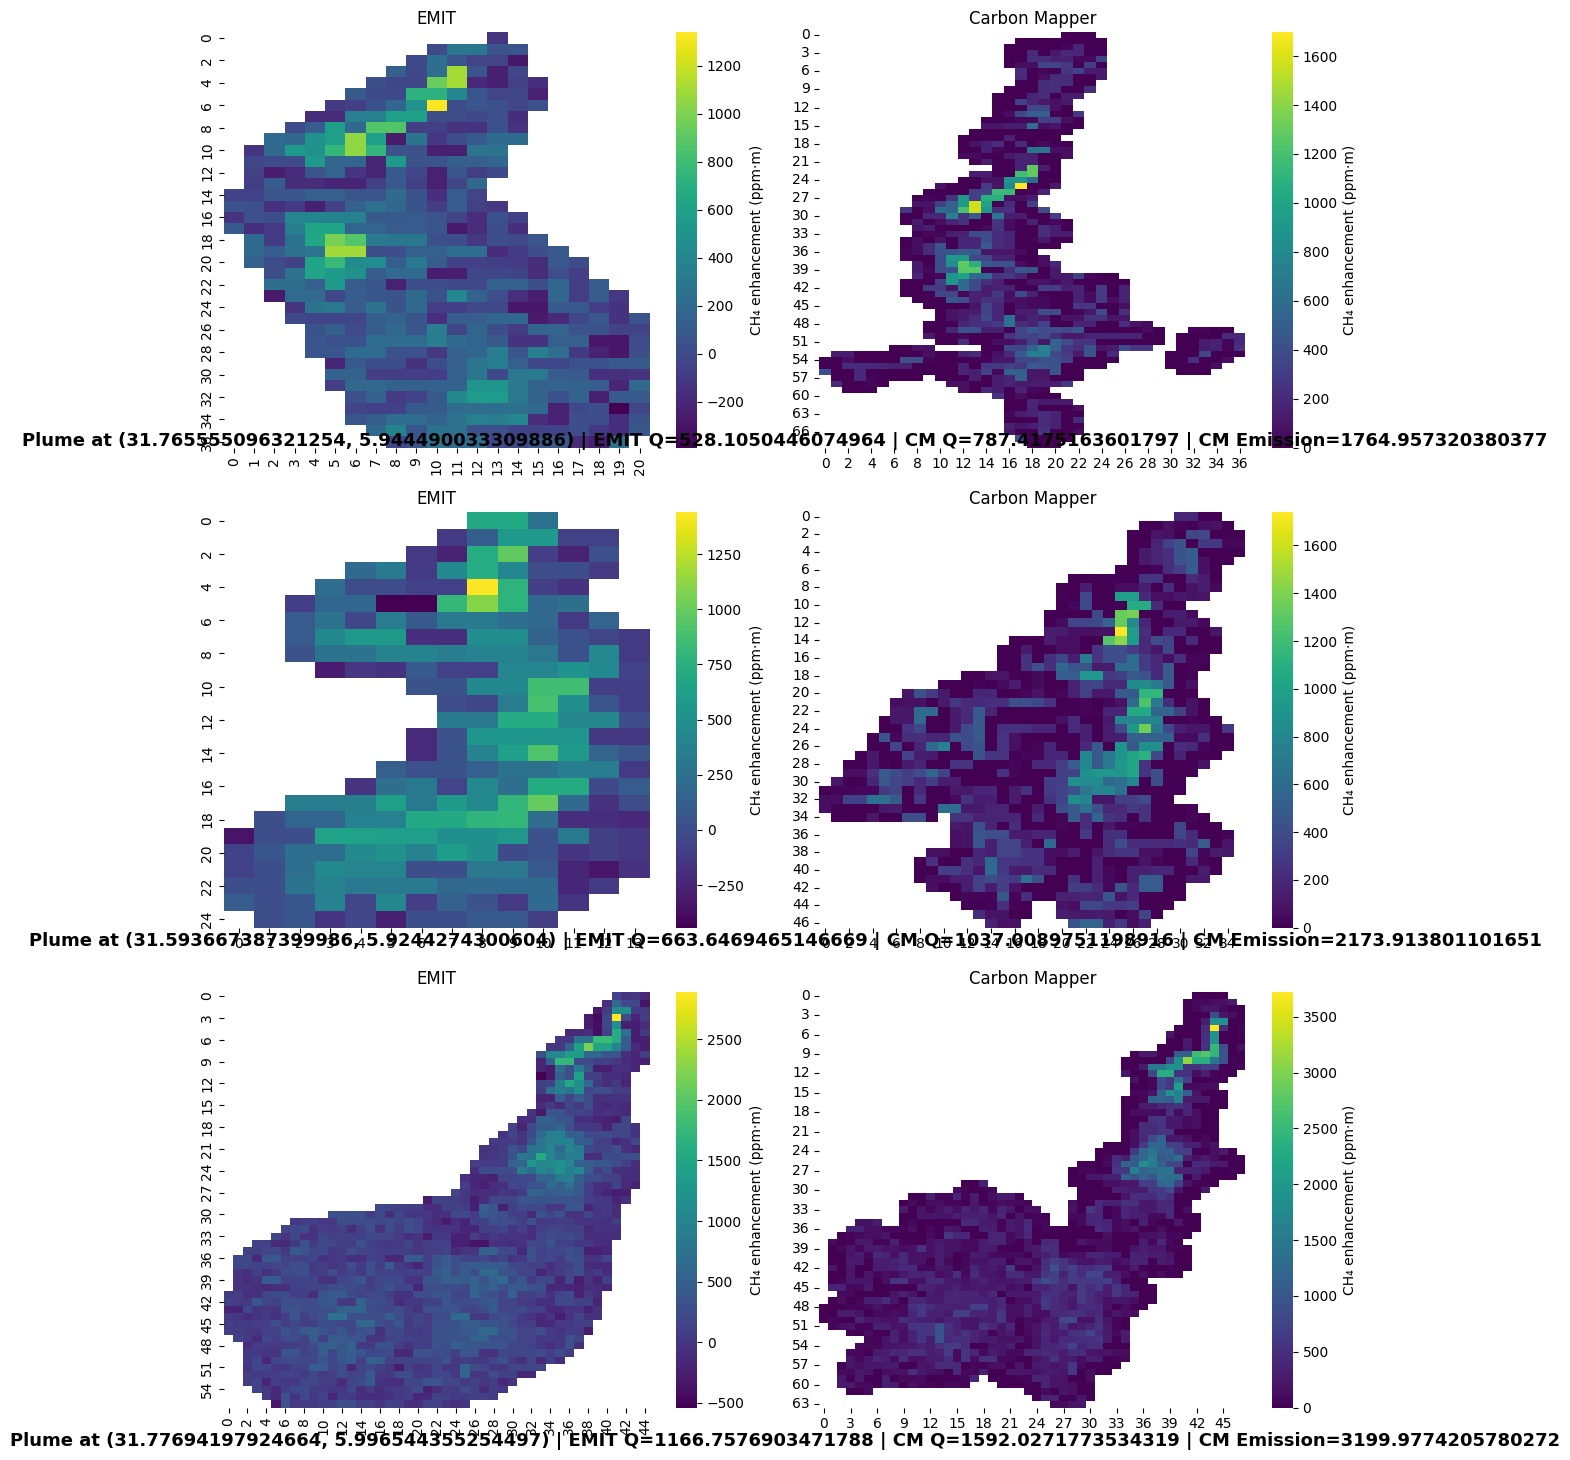

,emit_id,cm_id_x,emit_date,cm_date,distance_km,calculated_emit_Q,cm_emission,emit_coords,cm_coords,cm_con_tif,...,calculated_emit_plume_length,calculated_emit_area,emit_tif_path,cm_ime,cm_id_y,calculated_cm_Q,cm_tif_path,calculated_emit_calculated_cm_Q_error,calculated_emit_cm_Q_error,calculated_cm_Q_cm_emission_error
0,000775,emi20230330t125302p09038-B,2023-03-30,2023-03-30,0.132,528.105045,1764.957320,"(31.765555096321254, 5.944490033309886)","(31.76641309173033, 5.945450285491859)",https://catalog.carbonmapper.org/l3a-ch4-mfa-v...,...,986.301831,9.727913e+05,emit_ch4/EMITL2BCH4PLM/EMIT_L2B_CH4PLM_001_202...,NaN,NaN,787.417516,cm_plumes/emi20230330t125302p09038-B_l3a-ch4-m...,259.312472,1236.852276,977.539804
1,000778,emi20230330t125250p09037-A,2023-03-30,2023-03-30,0.188,663.646947,2173.913801,"(31.593667387399986, 5.9244274300604)","(31.59531702412899, 5.924880731179627)",https://catalog.carbonmapper.org/l3a-ch4-mfa-v...,...,728.243048,5.303379e+05,emit_ch4/EMITL2BCH4PLM/EMIT_L2B_CH4PLM_001_202...,126.167319,emi20230330t125250p09037-A,1037.008975,cm_plumes/emi20230330t125250p09037-A_l3a-ch4-m...,373.362029,1510.266855,1136.904826
2,000776,emi20230330t125302p09038-A,2023-03-30,2023-03-30,0.064,1166.757690,3199.977421,"(31.77694197924664, 5.996544355254497)","(31.7773195463472, 5.997056643592828)",https://catalog.carbonmapper.org/l3a-ch4-mfa-v...,...,1747.783316,3.054747e+06,emit_ch4/EMITL2BCH4PLM/EMIT_L2B_CH4PLM_001_202...,NaN,NaN,1592.027177,cm_plumes/emi20230330t125302p09038-A_l3a-ch4-m...,425.269487,2033.219730,1607.950243


In [11]:
def automatically_validate_calculated_emissions( emit_data_dir= "emit_ch4/EMITL2BCH4PLM", cm_plumes_dir = "cm_plumes", 
    sensing_time : str = "20230216",
    bbox = (5.027957, 30.72952, 7.027957, 32.72952),
    spatial_resolution: float = 55.05,
    wind_source=  "ERA5"):

    # 1. Emissions estimation  the EMIT plumes 
    emit_plumes = quantify_plumes(
    data_dir= emit_data_dir,
    sensing_time = sensing_time,
    bbox = bbox,
    spatial_resolution = spatial_resolution,
    wind_source=  wind_source
    )

    print( 'emit_plumes', len(emit_plumes))
    # 1. Get the Carbon mapper plumes with their emissions

    auth = CarbonMapperAuth(email="widad.belkadi@africaspaceworks.com", password='R+**C"V#7^cPcDv')
    auth.get_token_pair()
    formatted_date = f"{sensing_time[:4]}-{sensing_time[4:6]}-{sensing_time[6:]}"
    cm_plumes = get_carbonmapper_plumes(
    auth,
    start_date= f"{formatted_date}T00:00:00Z",
    end_date= f"{formatted_date}T23:59:00Z",
    bbox=bbox
    )
    print('cm plumes' , len(cm_plumes))
    # filter the plumes that has the emissions and concentration tif
    not_null_plumes = filter_null_plumes(cm_plumes)
    print('cm plumes filtered' , len(not_null_plumes))
    # correpondance 
    df_matches = match_plumes(emit_plumes, not_null_plumes, max_km=1, date_tolerance_days=0)

    if len(df_matches) >0:

        ## @TODO get the IME from  
        df_ime = get_IME_data(start_date =  formatted_date,end_date =  formatted_date,  bbox = bbox)
        if len(df_ime)> 0:
            df_matches["cm_date"] = pd.to_datetime(df_matches["cm_date"]).dt.strftime("%Y-%m-%d")
            df_matches["cm_coords"] = df_matches["cm_coords"].apply(
                lambda c: tuple(c) if isinstance(c, (list, tuple)) else eval(c)
            )

            df_matches = df_matches.merge(df_ime, on=["cm_date", "cm_coords"], how="left")

        # Download the tif of each plume  + get the IME of each plume 

        df_matches = process_dataframe(df_matches, bbox = bbox, spatial_resolution = spatial_resolution, wind_source=  wind_source,  download_dir= cm_plumes_dir)

        ## calculate the error between the 
        df_matches['calculated_emit_calculated_cm_Q_error'] = abs(df_matches['calculated_emit_Q'] - df_matches['calculated_cm_Q'])
        df_matches['calculated_emit_cm_Q_error'] = abs(df_matches['calculated_emit_Q'] - df_matches['cm_emission'])
        df_matches['calculated_cm_Q_cm_emission_error'] = abs(df_matches['calculated_cm_Q'] - df_matches['cm_emission'])

        # visualize the cm and emit plumes 
        plot_emit_cm_heatmaps(df_matches, n_rows=len(df_matches))

    return df_matches

df_all = automatically_validate_calculated_emissions(sensing_time = "20230330")
df_all

In [ ]:
df_all[["calculated_cm_Q", "calculated_emit_Q", "cm_emission"]]

,calculated_cm_Q,calculated_emit_Q,cm_emission
0,787.417516,528.105045,1764.957320
1,1037.008975,663.646947,2173.913801
2,1592.027177,1166.757690,3199.977421
